In [31]:
import kagglehub
import pandas as pd

# Download latest version
path = kagglehub.dataset_download("saurabh00007/diabetescsv")

print("Path to dataset files:", path)
df=pd.read_csv(path+"/diabetes.csv")
#Inspect the data
display (df.head())
display(df.tail())
display(df.shape[0])
display(df.shape[1])
display(df.columns)
display(df.info())
display(df.describe())
display(df.isnull().sum())

Using Colab cache for faster access to the 'diabetescsv' dataset.
Path to dataset files: /kaggle/input/diabetescsv


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


768

9

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


None

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [32]:
import numpy as np
#REPLACE INVALID ZEROES
zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[zero_cols] = df[zero_cols].replace(0, np.nan)
print("Number of invalid zeros replaced with NaN in each column:")
display(df.isnull().sum())
for col in zero_cols:
    df[col] = df.groupby('Outcome')[col].transform(lambda x: x.fillna(x.median()))
print("\nMissing values after imputation:")
display(df.isnull().sum())
display(df.head())

Number of invalid zeros replaced with NaN in each column:


,0
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0



Missing values after imputation:


,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,169.5,33.6,0.627,50,1
1,1,85.0,66.0,29.0,102.5,26.6,0.351,31,0
2,8,183.0,64.0,32.0,169.5,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


In [33]:
from sklearn.model_selection import train_test_split
#train_test_split
X = df.drop(columns=['Outcome'])
y = df['Outcome']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")
print(f"Training target shape: {y_train.shape}")
print(f"Testing target shape: {y_test.shape}")

Training features shape: (614, 8)
Testing features shape: (154, 8)
Training target shape: (614,)
Testing target shape: (154,)


In [34]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
#median imputation
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)
print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

Accuracy Score: 0.8636

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.90      0.90       100
           1       0.81      0.80      0.80        54

    accuracy                           0.86       154
   macro avg       0.85      0.85      0.85       154
weighted avg       0.86      0.86      0.86       154



In [35]:
from sklearn.preprocessing import StandardScaler
#Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns)
display(X_train_scaled_df.head())
print("Features scaled successfully!")

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,-0.851355,-1.056869,-0.826687,-1.895290,-1.170378,-0.766150,0.310794,-0.792169
1,0.356576,0.142855,0.477009,-0.224736,-1.427642,-0.414448,-0.116439,0.561034
2,-0.549372,-0.556984,-1.152611,1.223078,-0.545594,0.362227,-0.764862,-0.707594
3,-0.851355,0.809369,-1.315573,-0.224736,-0.441463,-0.399794,0.262314,-0.369293
4,-1.153338,-0.890241,-0.663725,1.111708,-0.410836,1.783690,-0.337630,-0.961320


Features scaled successfully!


In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score
#Train Logistic Regression
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_scaled, y_train)
y_pred_lr = log_reg.predict(X_test_scaled)
# Evaluate performance
print(f"Logistic Regression Accuracy: {accuracy_score(y_test, y_pred_lr):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Accuracy: 0.7078

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.79      0.78       100
           1       0.59      0.56      0.57        54

    accuracy                           0.71       154
   macro avg       0.68      0.67      0.67       154
weighted avg       0.70      0.71      0.71       154



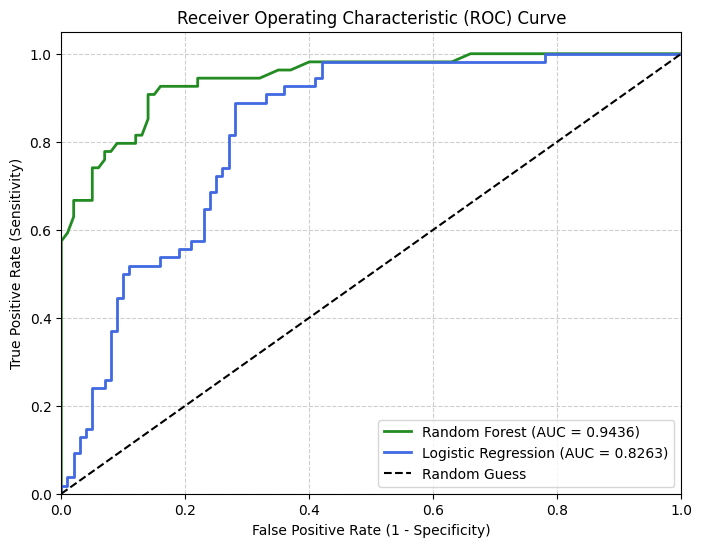

,Metric,Random Forest (Baseline),Logistic Regression (Scaled)
0,Accuracy,0.8636,0.7078
1,Precision (Class 1),0.8113,0.5882
2,Recall (Class 1),0.7963,0.5556
3,F1-Score (Class 1),0.8037,0.5714
4,AUC-ROC,0.9436,0.8263


In [37]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_fscore_support
import pandas as pd

# Calculate probabilities
y_pred_prob_rf = rf_model.predict_proba(X_test)[:, 1]
y_pred_prob_lr = log_reg.predict_proba(X_test_scaled)[:, 1]

# Calculate ROC curves
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_prob_rf)
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_pred_prob_lr)

# Calculate AUC scores
auc_rf = roc_auc_score(y_test, y_pred_prob_rf)
auc_lr = roc_auc_score(y_test, y_pred_prob_lr)

# Plot ROC Curves
plt.figure(figsize=(8, 6))
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.4f})', color='forestgreen', lw=2)
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {auc_lr:.4f})', color='royalblue', lw=2)
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Build a comparison DataFrame
metrics_rf = precision_recall_fscore_support(y_test, y_pred, average='binary')
metrics_lr = precision_recall_fscore_support(y_test, y_pred_lr, average='binary')

comparison_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision (Class 1)', 'Recall (Class 1)', 'F1-Score (Class 1)', 'AUC-ROC'],
    'Random Forest (Baseline)': [
        accuracy_score(y_test, y_pred),
        metrics_rf[0],
        metrics_rf[1],
        metrics_rf[2],
        auc_rf
    ],
    'Logistic Regression (Scaled)': [
        accuracy_score(y_test, y_pred_lr),
        metrics_lr[0],
        metrics_lr[1],
        metrics_lr[2],
        auc_lr
    ]
})

display(comparison_df.round(4))

Logistic Regression Coefficients (Sorted by Impact):


,Feature,Coefficient
1,Glucose,0.934942
4,Insulin,0.614170
5,BMI,0.466051
0,Pregnancies,0.337228
3,SkinThickness,0.294976
6,DiabetesPedigreeFunction,0.174725
7,Age,0.159826
2,BloodPressure,-0.004245


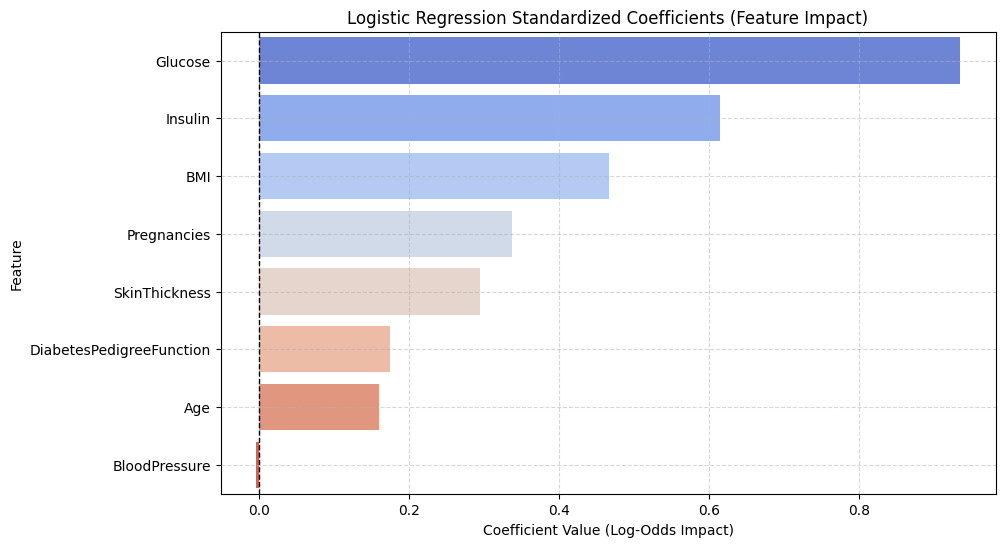

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
#interpret coefficients.
coefficients = log_reg.coef_[0]
features = X.columns
coef_df = pd.DataFrame({
    'Feature': features,
    'Coefficient': coefficients,
    'Abs_Coefficient': np.abs(coefficients)
}).sort_values(by='Abs_Coefficient', ascending=False)

print("Logistic Regression Coefficients (Sorted by Impact):")
display(coef_df[['Feature', 'Coefficient']])
plt.figure(figsize=(10, 6))
sns.barplot(x='Coefficient', y='Feature', data=coef_df.sort_values(by='Coefficient', ascending=False), palette='coolwarm', hue='Feature', legend=False)
plt.axvline(0, color='black', linestyle='--', linewidth=1)
plt.title('Logistic Regression Standardized Coefficients (Feature Impact)')
plt.xlabel('Coefficient Value (Log-Odds Impact)')
plt.ylabel('Feature')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()